In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

df = pd.read_csv("trustpilot_reviews_2005.csv")
df.head()

,category,company,description,title,review,stars
0,Animals & Pets,ruffandtumbledogcoats.com,At Ruff and Tumble we are proud to be the mark...,Great quality dog drying robe although…,Great quality dog drying robe although had to ...,5
1,Animals & Pets,ruffandtumbledogcoats.com,At Ruff and Tumble we are proud to be the mark...,Really prompt service,"Really prompt service, The sofa covers have no...",5
2,Animals & Pets,ruffandtumbledogcoats.com,At Ruff and Tumble we are proud to be the mark...,Life saver,I’ve purchased first of those coats in May2020...,5
3,Animals & Pets,ruffandtumbledogcoats.com,At Ruff and Tumble we are proud to be the mark...,Brilliant coats,Brilliant coats. Really like the limited editi...,5
4,Animals & Pets,ruffandtumbledogcoats.com,At Ruff and Tumble we are proud to be the mark...,Great company and products,Great company and products. This is my 3rd dry...,5


In [2]:
df.shape

(123181, 6)

In [3]:
df.columns.tolist()

['category', 'company', 'description', 'title', 'review', 'stars']

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 123181 entries, 0 to 123180
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   category     123181 non-null  str  
 1   company      123181 non-null  str  
 2   description  123181 non-null  str  
 3   title        123181 non-null  str  
 4   review       123181 non-null  str  
 5   stars        123181 non-null  int64
dtypes: int64(1), str(5)
memory usage: 5.6 MB


In [5]:
df.isnull().sum()

category       0
company        0
description    0
title          0
review         0
stars          0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
scope_categories = [
    'Shopping & Fashion',
    'Electronics & Technology',
    'Home & Garden'
]

df = df[df['category'].isin(scope_categories)].copy()

print("Working dataset:", df.shape)
print("Categories:", df['category'].unique().tolist())

Working dataset: (17531, 6)
Categories: ['Shopping & Fashion', 'Home & Garden', 'Electronics & Technology']


In [8]:
df['stars'].unique()

array([5, 4, 3, 2, 1])

 Rating Distribution

In [9]:
df['stars'].unique()

array([5, 4, 3, 2, 1])

In [10]:
rating_counts = df['stars'].value_counts().sort_index()
rating_counts

stars
1    3311
2    3036
3    3240
4    3750
5    4194
Name: count, dtype: int64

In [11]:
rating_percentages = df['stars'].value_counts(normalize=True).sort_index().mul(100).round(2)
rating_percentages

stars
1    18.89
2    17.32
3    18.48
4    21.39
5    23.92
Name: proportion, dtype: float64

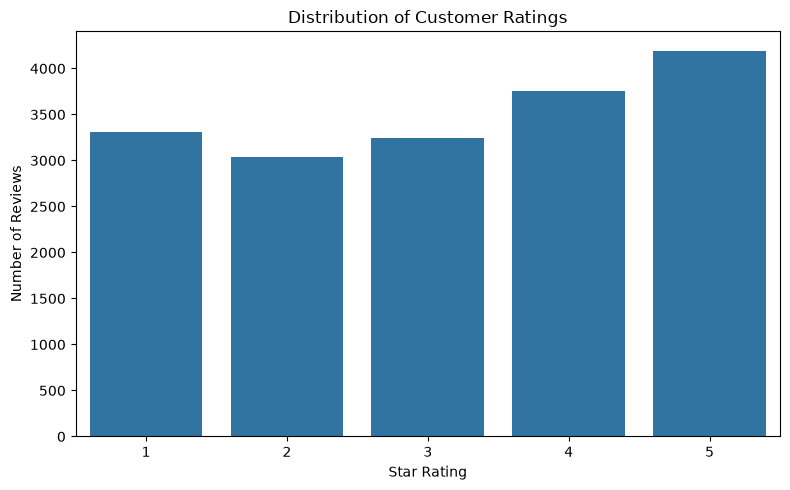

In [12]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='stars')
plt.title('Distribution of Customer Ratings')
plt.xlabel('Star Rating')
plt.ylabel('Number of Reviews')
plt.tight_layout()
plt.show()

In [13]:
df['review_word_count'] = df['review'].astype(str).str.split().str.len()
df['review_word_count'].describe()

count    17531.000000
mean        62.010382
std         50.526577
min          2.000000
25%         31.000000
50%         51.000000
75%         77.000000
max        933.000000
Name: review_word_count, dtype: float64

In [14]:
df.groupby('stars')['review_word_count'].describe()

,count,mean,std,min,25%,50%,75%,max
stars,,,,,,,,
1,3311.0,80.525219,69.388428,2.0,40.0,65.0,100.00,933.0
2,3036.0,74.658762,56.078154,3.0,39.0,62.0,91.25,654.0
3,3240.0,66.043519,49.531372,4.0,36.0,56.0,82.00,794.0
4,3750.0,50.167467,34.937206,2.0,26.0,43.0,65.00,399.0
5,4194.0,45.711016,28.624979,2.0,26.0,40.0,59.00,305.0


In [15]:
critical_reviews = df[df['stars'].isin([1, 2])].copy()

print("Critical reviews:", len(critical_reviews))
print("1-star reviews:", (critical_reviews['stars'] == 1).sum())
print("2-star reviews:", (critical_reviews['stars'] == 2).sum())

Critical reviews: 6347
1-star reviews: 3311
2-star reviews: 3036


In [16]:
critical_percentage = len(critical_reviews) / len(df) * 100
one_star_percentage = (critical_reviews['stars'] == 1).mean() * 100
two_star_percentage = (critical_reviews['stars'] == 2).mean() * 100

print(f"Critical reviews (1–2 stars): {critical_percentage:.2f}%")
print(f"1-star share of critical reviews: {one_star_percentage:.2f}%")
print(f"2-star share of critical reviews: {two_star_percentage:.2f}%")

Critical reviews (1–2 stars): 36.20%
1-star share of critical reviews: 52.17%
2-star share of critical reviews: 47.83%


Text cleaning

A separate review_clean column is created so the original review remains available for audit and GenAI prompting. Cleaning standardizes case, removes HTML tags and special characters, and normalizes whitespace.

In [17]:
df['review_clean'] = (
    df['review'].astype(str)
    .str.lower()
    .str.replace(r'<.*?>', ' ', regex=True)
    .str.replace(r"[^a-z0-9\s'’]", ' ', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

# Recreate the critical-review subset after text cleaning
critical_reviews = df[df['stars'].isin([1, 2])].copy()

df[['review', 'review_clean']].head()

,review,review_clean
4975,"All good , present for Christmas didn’t think ...",all good present for christmas didn’t think it...
4976,I booked next day delivery on 23rd December ex...,i booked next day delivery on 23rd december ex...
4977,I have made 2 visits with things brought onlin...,i have made 2 visits with things brought onlin...
4978,It was my first time ordering through flannels...,it was my first time ordering through flannels...
4979,The lady I spoke to at customer service was am...,the lady i spoke to at customer service was am...


Document-Frequency Complaint Keywords

A simple token count can be misleading because one long review can repeat the same word many times. Therefore, each review contributes at most one count per word. The percentage below means the percentage of critical reviews containing the term.
Negations such as not, no, and never are retained because they can carry complaint meaning.

In [18]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

extra_stopwords = {
    'just','did','got','said','told','like','really',
    'also','get','will','would','good','use'
}
stopwords = set(ENGLISH_STOP_WORDS) | extra_stopwords
negations = {'not','no','never','nothing','without','cannot'}
bigram_stopwords = stopwords - negations

def document_frequency(texts):
    counts = Counter()
    for text in texts:
        counts.update({
            word for word in text.split()
            if word not in stopwords
            and len(word) > 2
            and not word.isdigit()
        })
    return counts

word_counts = document_frequency(critical_reviews['review_clean'])
n_critical = len(critical_reviews)

top_keywords = [
    (word, count, round(count / n_critical * 100, 1))
    for word, count in word_counts.most_common(15)
]

top_keywords

[('service', 1516, 23.9),
 ('delivery', 1491, 23.5),
 ('customer', 1371, 21.6),
 ('order', 1338, 21.1),
 ('ordered', 1331, 21.0),
 ('time', 1189, 18.7),
 ('company', 1065, 16.8),
 ('received', 973, 15.3),
 ('days', 892, 14.1),
 ('refund', 886, 14.0),
 ('day', 841, 13.3),
 ('sent', 774, 12.2),
 ('item', 773, 12.2),
 ('arrived', 753, 11.9),
 ('email', 735, 11.6)]

Top Complaint Keywords
Keyword	Reviews containing word	% of critical reviews
service	1,516	23.9%
delivery	1,491	23.5%
customer	1,371	21.6%
order	1,338	21.1%
ordered	1,331	21.0%
time	1,189	18.7%
company	1,065	16.8%
received	973	15.3%
days	892	14.1%
refund	886	14.0%
day	841	13.3%
sent	774	12.2%
item	773	12.2%
arrived	753	11.9%
email	735	11.6%

Complaint Phrases

In [19]:
def bigram_frequency(texts):
    counts = Counter()
    for text in texts:
        words = text.split()
        counts.update({
            f"{a} {b}"
            for a, b in zip(words, words[1:])
            if a not in bigram_stopwords
            and b not in bigram_stopwords
            and not a.isdigit()
            and not b.isdigit()
        })
    return counts

bigram_counts = bigram_frequency(critical_reviews['review_clean'])
top_bigrams = [
    (phrase, count, round(count / n_critical * 100, 1))
    for phrase, count in bigram_counts.most_common(10)
]
top_bigrams

[('customer service', 895, 14.1),
 ('day delivery', 212, 3.3),
 ('customer services', 197, 3.1),
 ('days later', 169, 2.7),
 ('no response', 165, 2.6),
 ('not received', 144, 2.3),
 ('does not', 133, 2.1),
 ('not recommend', 120, 1.9),
 ('poor quality', 114, 1.8),
 ('no longer', 104, 1.6)]

Top Complaint Phrases
Complaint phrase	Reviews containing phrase	% of critical reviews
customer service	895	14.1%
day delivery	212	3.3%
customer services	197	3.1%
days later	169	2.7%
no response	165	2.6%
not received	144	2.3%
does not	133	2.1%
not recommend	120	1.9%
poor quality	114	1.8%
no longer	104	1.6%

One-Star vs Two-Star Comparison

In [20]:
one_star_reviews = critical_reviews[critical_reviews['stars'] == 1].copy()
two_star_reviews = critical_reviews[critical_reviews['stars'] == 2].copy()

one_counts = document_frequency(one_star_reviews['review_clean'])
two_counts = document_frequency(two_star_reviews['review_clean'])

selected_terms = ['service','delivery','order','customer','money','refund','received','company','time']

comparison_rows = []
for term in selected_terms:
    comparison_rows.append([
        term,
        round(one_counts[term] / len(one_star_reviews) * 100, 2),
        round(two_counts[term] / len(two_star_reviews) * 100, 2)
    ])

keyword_comparison = pd.DataFrame(
    comparison_rows,
    columns=['Keyword','1-star review %','2-star review %']
)

keyword_comparison

,Keyword,1-star review %,2-star review %
0,service,27.51,19.93
1,delivery,22.20,24.90
2,order,23.14,18.84
3,customer,25.10,17.79
4,money,12.44,7.02
5,refund,17.43,10.18
6,received,17.37,13.11
7,company,20.96,12.22
8,time,18.54,18.94


Complaint Category Analysis

In [21]:
complaint_keywords = {
    'delivery': ['delivery','delivered','arrived','shipping','shipment','courier','dispatch','delay','delayed'],
    'order': ['order','ordered','purchase','ordering'],
    'refund_payment': ['refund','money','payment','charged','charge','refunds'],
    'customer_service': ['support','communication','response','responded','reply','replied','callback','contact','ignored'],
    'product_quality': ['faulty','damaged','broken','defective','poor','quality','malfunction']
}

def contains_category_keyword(text, keywords):
    words = set(text.split())
    return any(keyword in words for keyword in keywords)

category_counts = {
    category: sum(
        contains_category_keyword(text, keywords)
        for text in critical_reviews['review_clean']
    )
    for category, keywords in complaint_keywords.items()
}

category_summary = pd.DataFrame(
    list(category_counts.items()),
    columns=['Complaint Category','Critical Reviews']
)
category_summary['Percentage of Critical Reviews'] = (
    category_summary['Critical Reviews'] / len(critical_reviews) * 100
).round(2)

category_summary

,Complaint Category,Critical Reviews,Percentage of Critical Reviews
0,delivery,2531,39.88
1,order,2585,40.73
2,refund_payment,1663,26.20
3,customer_service,1459,22.99
4,product_quality,1490,23.48


Complaint Category Summary
Complaint Category	Critical Reviews	% of Critical Reviews
delivery	2,531	39.88%
order	2,585	40.73%
refund_payment	1,663	26.20%
customer_service	1,459	22.99%
product_quality	1,490	23.48%

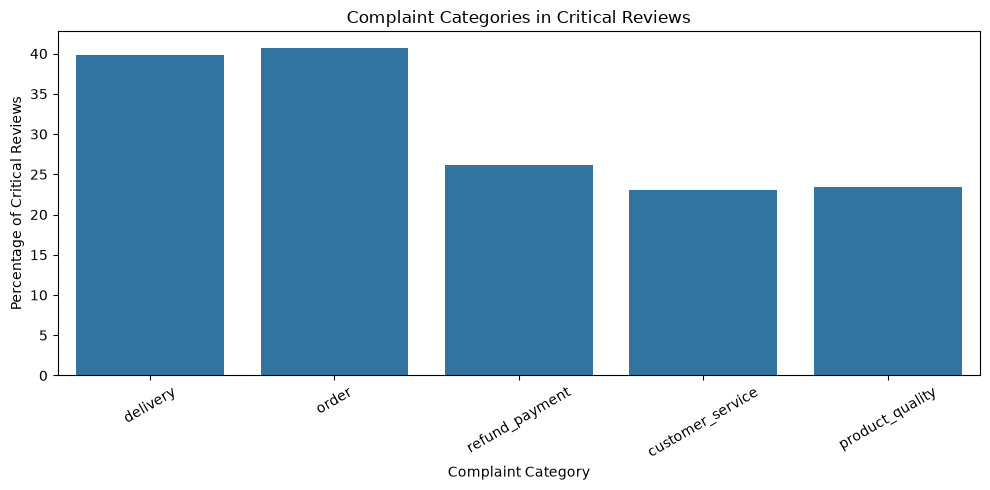

In [22]:
plt.figure(figsize=(10,5))
sns.barplot(
    data=category_summary,
    x='Complaint Category',
    y='Percentage of Critical Reviews'
)
plt.title('Complaint Categories in Critical Reviews')
plt.xlabel('Complaint Category')
plt.ylabel('Percentage of Critical Reviews')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Critical-Review Rate by Business Category

In [23]:
category_rate = (
    df.groupby('category')['stars']
    .agg(
        total_reviews='size',
        critical_reviews=lambda x: x.isin([1,2]).sum()
    )
    .reset_index()
)

category_rate['critical_rate_pct'] = (
    category_rate['critical_reviews'] /
    category_rate['total_reviews'] * 100
).round(2)

category_rate.sort_values('critical_rate_pct', ascending=False)

,category,total_reviews,critical_reviews,critical_rate_pct
2,Shopping & Fashion,5794,2166,37.38
1,Home & Garden,6141,2209,35.97
0,Electronics & Technology,5596,1972,35.24


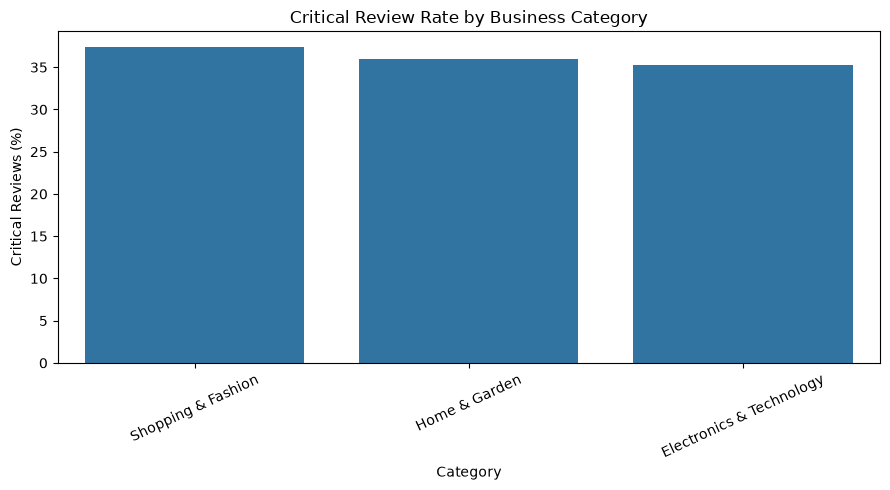

In [24]:
plt.figure(figsize=(9,5))
sns.barplot(
    data=category_rate.sort_values('critical_rate_pct', ascending=False),
    x='category',
    y='critical_rate_pct'
)
plt.title('Critical Review Rate by Business Category')
plt.xlabel('Category')
plt.ylabel('Critical Reviews (%)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

Explainable Rule-Based Priority Score

The priority score uses three transparent signals:
- 1-star severity: +3 points
- Explicit severity phrases: up to +6 points using scam, fraud, never arrived, still waiting, trading standards, solicitor, and chargeback
- Review detail: log(1 + word_count) gives a continuous contribution instead of a binary long/short flag
This reduces large groups of tied scores and makes the selection logic easier to defend in an interview.

In [25]:
severe_phrases = [
    'scam','fraud','never arrived','still waiting',
    'trading standards','solicitor','chargeback'
]

critical_reviews['severity_hits'] = critical_reviews['review_clean'].apply(
    lambda text: sum(phrase in text for phrase in severe_phrases)
)

critical_reviews['priority_score'] = (
    (critical_reviews['stars'] == 1).astype(int) * 3
    + critical_reviews['severity_hits'].clip(upper=3) * 2
    + np.log1p(critical_reviews['review_word_count'])
)

top_3_reviews = critical_reviews.sort_values(
    ['priority_score','review_word_count'],
    ascending=[False,False]
).head(3).copy()

top_3_reviews[
    ['category','company','stars','title',
     'review_word_count','severity_hits','priority_score']
]

,category,company,stars,title,review_word_count,severity_hits,priority_score
32359,Electronics & Technology,www.currys.co.uk,1,I'm contacting trading standards and…,88,3,13.488636
117821,Shopping & Fashion,www.decathlon.co.uk,1,DON'T BUY FROM THEIR MARKETPLACE,183,2,12.214936
33031,Electronics & Technology,softwaresupply.net,1,"Avoid, resells username and passwords",178,2,12.187386


In [26]:
top_3_reviews[['category','company','stars','title','review_word_count','severity_hits','priority_score','review']]

,category,company,stars,title,review_word_count,severity_hits,priority_score,review
32359,Electronics & Technology,www.currys.co.uk,1,I'm contacting trading standards and…,88,3,13.488636,I'm contacting trading standards and going to ...
117821,Shopping & Fashion,www.decathlon.co.uk,1,DON'T BUY FROM THEIR MARKETPLACE,183,2,12.214936,DON'T BUY FROM THEIR MARKETPLACEAbsolute worse...
33031,Electronics & Technology,softwaresupply.net,1,"Avoid, resells username and passwords",178,2,12.187386,Update:Sellers response here proves the level ...


Generative AI Response Generation

In [ ]:
from google import genai
from getpass import getpass

api_key = getpass("Enter your Gemini API key: ")
client = genai.Client(api_key=api_key)

In [ ]:
generated_emails = []

for index, row in top_3_reviews.iterrows():

    prompt = f"""
You are a professional customer support agent for {row['company']}.

Write a personalized, empathetic customer-support apology email based
ONLY on the customer review provided below.

Requirements:
- Write 120-160 words.
- Reference at least TWO concrete facts from the review, such as a
  product name, date, amount, order detail, delivery time, or number
  of contacts.
- Clearly acknowledge the customer's specific problems.
- Be empathetic and professional.
- Do NOT invent refunds, replacements, compensation, investigations,
  policies, or actions.
- Do NOT promise a specific resolution that is not stated in the review.
- Do NOT simply repeat the review.
- Sign off as "{row['company']} Customer Support".
- Include a suitable subject line.

Review title:
{row['title']}

Customer review:
{row['review']}

Write only the email.
"""

    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=prompt
    )

    if response.text and response.text.strip():
        generated_emails.append(response.text.strip())
    else:
        generated_emails.append(
            "ERROR: Gemini returned an empty response for this review."
        )

print("Generated responses:", len(generated_emails))

Generated responses: 3


In [ ]:
for i, email in enumerate(generated_emails, start=1):
    print(f"\n{'='*80}")
    print(f"RESPONSE {i}")
    print('='*80)
    print(email)


RESPONSE 1
Subject: Your Currys refund enquiry

Dear Customer,

Thank you for getting in touch. I am truly sorry for the extreme frustration and distress you have experienced regarding your outstanding refund of £59.99. 

I completely understand your anger at still waiting for your money since 14th December 2024. It is unacceptable that you have felt ignored after emailing us quite a few times, and I am very sorry that the callback promised within 24 hours after your phone call did not happen. Being left without your money and feeling repeatedly let down by our service is not the experience we want you to have with Currys. 

We take your concerns extremely seriously. I hear how upset you are about this situation and the communication failures you have faced. 

Thank you for bringing this to our attention.

Sincerely,

www.currys.co.uk Customer Support

RESPONSE 2
Subject: Regarding your recent experience with your marketplace order

Dear Customer,

Thank you for reaching out to us. I 

In [ ]:
print("Number of generated emails:", len(generated_emails))

Number of generated emails: 3


In [ ]:
print(generated_emails[2])

Subject: Following up regarding your Office 365 purchase and recent support experience

Dear Customer,

Thank you for reaching out, and I am truly sorry to hear about your frustrating experience with us. We completely understand your concerns regarding purchasing Office 365 usernames and passwords instead of license keys, as well as the anxiety caused by being instructed to change the password upon receipt. 

We also sincerely apologize that your follow-up emails were ignored by our support team, and that our previous response felt unprofessional and dismissive of your personal identity. We deeply regret that the promises made to you were not met and that you had to resort to a chargeback through your credit card company. We hear your feedback loud and clear regarding our sales wording, warranty practices, and the overall transparency of our product pages, and we are taking your comments very seriously. 

Sincerely,

softwaresupply.net Customer Support


In [ ]:
top_3_reviews[
    ['stars','company','title','review_word_count',
     'priority_score','AI_Response']
].to_csv("top_3_genai_responses.csv", index=False)

AI-Generated Response Emails

RESPONSE 1

Subject: Regarding your Currys refund and recent experience

Dear Customer,

Thank you for reaching out to us. I am very sorry for the frustration and stress you have experienced regarding your £59.99 refund since 14th December 2024. 

We completely understand how upsetting it is to feel ignored, especially after emailing multiple times and being told a call would happen within 24 hours without anyone getting back to you. This is certainly not the level of service we aim to provide, and I hear your anger regarding the lack of communication and the delay in receiving your money back. 

We take your concerns very seriously, and we recognize how frustrating this situation has become for you. Thank you for bringing this to our attention. 

www.currys.co.uk Customer Support

RESPONSE 2

Subject: Regarding your recent experience with www.decathlon.co.uk

Dear Customer,

Thank you for contacting www.decathlon.co.uk Customer Support. We are truly sorry to hear about your recent experience and fully understand your frustration. 

It is completely disheartening to wait a month to return an item, especially when you spent £315 of your own money on a bike you urgently need for daily travel. We also recognize how upsetting it is to receive a damaged and faulty bike with an overtightened back hub, and to feel that your concerns were not properly addressed during your communications with us and the third party. 
...
Sincerely,

softwaresupply.net Customer Support

Output is truncated. View as a scrollable element or open in a text editor. Adjust cell output settings...

RESPONSE 3

Subject: Following up regarding your Office 365 purchase and recent support experience

Dear Customer,

Thank you for reaching out, and I am truly sorry to hear about your frustrating experience with us. We completely understand your concerns regarding purchasing Office 365 usernames and passwords instead of license keys, as well as the anxiety caused by being instructed to change the password upon receipt. 

We also sincerely apologize that your follow-up emails were ignored by our support team, and that our previous response felt unprofessional and dismissive of your personal identity. We deeply regret that the promises made to you were not met and that you had to resort to a chargeback through your credit card company. We hear your feedback loud and clear regarding our sales wording, warranty practices, and the overall transparency of our product pages, and we are taking your comments very seriously. 

Sincerely,

softwaresupply.net Customer Support

AI Response Quality Checks

In [ ]:
def response_quality_check(row, email):
    lower = email.lower()
    subject_ok = 'subject:' in lower
    word_count = len(email.split())
    length_ok = 100 <= word_count <= 180
    company_ok = row['company'].lower() in lower

    prohibited = [
        'we have issued your refund',
        'we have processed your refund',
        'we will replace',
        'we have arranged a replacement',
        'compensation has been'
    ]
    prohibited_ok = not any(p in lower for p in prohibited)

    detail_ok = any(
        term in lower
        for term in [
            'delivery','refund','order','damaged',
            'broken','waiting','chargeback'
        ]
    )

    return pd.Series({
        'subject_present': subject_ok,
        'word_count': word_count,
        'length_ok': length_ok,
        'company_mentioned': company_ok,
        'specific_detail_present': detail_ok,
        'no_unsupported_resolution': prohibited_ok,
        'overall_pass': all([subject_ok,length_ok,company_ok,detail_ok,prohibited_ok])
    })

# Run this cell after Gemini generation.
quality_checks = pd.concat(
    [
        response_quality_check(row, email)
        for (_, row), email in zip(top_3_reviews.iterrows(), top_3_reviews['AI_Response'])
    ],
    axis=1
).T.reset_index(drop=True)

quality_checks

,subject_present,word_count,length_ok,company_mentioned,specific_detail_present,no_unsupported_resolution,overall_pass
0,True,126,True,True,True,True,True
1,True,139,True,True,True,True,True
2,True,126,True,True,True,True,True


Key Business Insights
1. Focused retail scope: The working dataset contains 17,531 reviews from Shopping & Fashion, Electronics & Technology, and Home & Garden.
2. Critical feedback volume: 6,347 reviews (36.20%) are rated 1 or 2 stars.
3. Rating severity: 1-star reviews represent 52.17% of critical reviews, while 2-star reviews represent 47.83%.
4. Complaint terms: The strongest document-frequency signals include service, delivery, customer, order, ordered, time.
5. Complaint phrases: More specific recurring phrases include customer service, day delivery, customer services, days later, no response.
6. Prioritization: The score combines rating severity, explicit high-severity language, and review detail without machine learning.
7. GenAI safeguards: The prompt requires concrete review details and prohibits unsupported promises about refunds, replacements, compensation, policies, or investigations.

Conclusion
This project demonstrates an explainable customer-feedback automation pipeline using Python, Pandas, rule-based text analysis, and Generative AI.
The workflow narrows a multi-category review dataset to a retail-focused scope, cleans review text, identifies critical 1–2 star reviews, extracts complaint words and phrases using document frequency, compares 1-star and 2-star feedback, analyzes complaint categories, prioritizes urgent cases using a transparent score, and uses Google Gemini to draft personalized support emails.
The solution avoids unnecessary machine-learning complexity while demonstrating practical data analysis, rule-based decision logic, and responsible Generative AI use.